# Taller (propuesto) — Reconocimiento de caracteres manuscritos con otro conjunto de datos
**Inteligencia Computacional Aplicada · Maestría en Ciencias de la Información y las Comunicaciones · UDFJC**

Repita el flujo del cuaderno resuelto con **otro conjunto de datos**, complete los bloques `TODO` y presente un informe corto. Cada `TODO` tiene una verificación automática que le dice `[OK]` o `[REVISAR]`.

| | |
|---|---|
| **Datasets (elija uno en la celda de configuración)** | `KMNIST` (caracteres manuscritos japoneses *kuzushiji*, 10 clases), `FashionMNIST` (prendas de vestir, 10 clases), `MNIST` (solo para comparar) |
| **Formato común** | Imágenes en escala de grises de 28×28, 60 000 de entrenamiento y 10 000 de prueba |

### Qué debe entregar
1. Este cuaderno completo y ejecutado (salidas visibles).




## Paso 0. Entorno y configuración

In [1]:
# ---- Preparación del entorno (Colab ya trae PyTorch, torchvision y scikit-learn) ----
import random, time, hashlib, os, shutil
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import confusion_matrix

SEMILLA = 42                      # misma semilla = mismos resultados (reproducibilidad)
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
fijar_semilla()

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", dispositivo)

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok


PyTorch 2.12.1+cu130 | dispositivo: cuda


In [2]:
# ---- CONFIGURACIÓN: cambie solo estas líneas ----
DATASET = "KMNIST"      # "KMNIST" | "FashionMNIST" | "MNIST"
EPOCAS  = 5

In [3]:
# ---- Funciones de datos (no necesita modificarlas) ----
def cargar_dataset(nombre="MNIST", raiz="datos"):
    """Descarga el conjunto con torchvision y devuelve tensores en [0,1] con forma N x 1 x 28 x 28.
    Si no hay internet, usa un conjunto de RESPALDO (digits de scikit-learn) y avisa."""
    from torchvision import datasets
    try:
        clase = getattr(datasets, nombre)
        tr = clase(raiz, train=True, download=True)
        te = clase(raiz, train=False, download=True)
        Xtr = tr.data.float().div(255).unsqueeze(1)
        Xte = te.data.float().div(255).unsqueeze(1)
        return Xtr, tr.targets.clone(), Xte, te.targets.clone(), list(tr.classes), False
    except Exception as e:
        print("AVISO: no se pudo descargar", nombre, "->", type(e).__name__)
        print("Se usa un conjunto de RESPALDO (sklearn digits: 1797 imágenes 8x8 escaladas a 28x28).")
        print("Sirve para probar el código, pero NO es", nombre, "y las exactitudes serán distintas.")
        from sklearn.datasets import load_digits
        d = load_digits()
        X = torch.tensor(d.images, dtype=torch.float32).div(16).unsqueeze(1)
        X = F.interpolate(X, size=28, mode="bilinear", align_corners=False)
        y = torch.tensor(d.target, dtype=torch.long)
        g = torch.Generator().manual_seed(SEMILLA)
        p = torch.randperm(len(y), generator=g)
        n_te = len(y) // 5
        return X[p[n_te:]], y[p[n_te:]], X[p[:n_te]], y[p[:n_te]], [str(i) for i in range(10)], True


def preparar_datos(nombre="MNIST", n_val=5000, batch=64):
    """Carga, separa entrenamiento/validación/prueba y normaliza SOLO con estadísticos de entrenamiento."""
    Xtr, ytr, Xte, yte, clases, respaldo = cargar_dataset(nombre)
    n_val = min(n_val, len(ytr) // 10)
    g = torch.Generator().manual_seed(SEMILLA)
    p = torch.randperm(len(ytr), generator=g)
    iv, it = p[:n_val], p[n_val:]
    Xt, yt, Xv, yv = Xtr[it], ytr[it], Xtr[iv], ytr[iv]
    media, desv = Xt.mean().item(), Xt.std().item()
    norm = lambda X: (X - media) / desv
    d = dict(nombre=nombre, clases=clases, respaldo=respaldo, media=media, desv=desv,
             Xraw_tr=Xt, Xraw_te=Xte,
             X_tr=norm(Xt), y_tr=yt, X_val=norm(Xv), y_val=yv, X_te=norm(Xte), y_te=yte)
    d["dl_tr"] = DataLoader(TensorDataset(d["X_tr"], yt), batch_size=batch, shuffle=True, generator=g)
    d["dl_val"] = DataLoader(TensorDataset(d["X_val"], yv), batch_size=512)
    d["dl_te"] = DataLoader(TensorDataset(d["X_te"], d["y_te"]), batch_size=512)
    return d


def mostrar_muestras(X, y, clases, n=16, titulo=""):
    fig, ejes = plt.subplots(2, n // 2, figsize=(1.4 * n // 2, 3.2))
    for ax, i in zip(ejes.ravel(), range(n)):
        ax.imshow(X[i, 0], cmap="gray"); ax.set_title(clases[int(y[i])], fontsize=9); ax.axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()


Dataset: KMNIST | clases: ['o', 'ki', 'su', 'tsu', 'na', 'ha', 'ma', 'ya', 're', 'wo']
Entrenamiento: (55000, 1, 28, 28) | Validación: (5000, 1, 28, 28) | Prueba: (10000, 1, 28, 28)


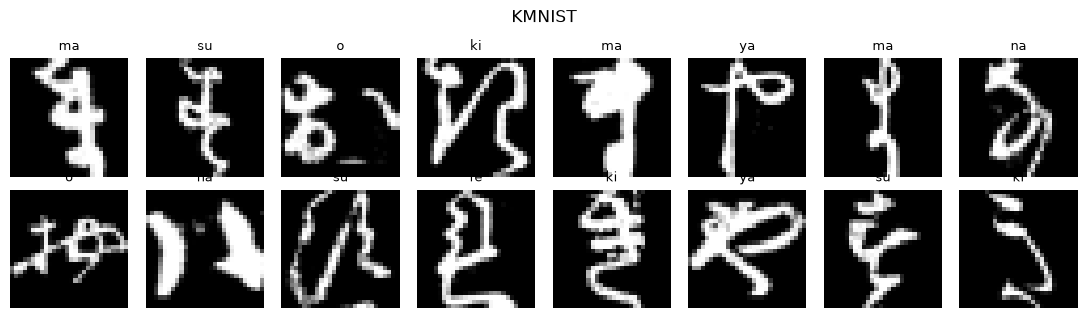

In [4]:
datos = preparar_datos(DATASET)
clases = datos["clases"]
print("Dataset:", DATASET, "| clases:", clases)
print("Entrenamiento:", tuple(datos["X_tr"].shape), "| Validación:", tuple(datos["X_val"].shape), "| Prueba:", tuple(datos["X_te"].shape))
mostrar_muestras(datos["Xraw_tr"], datos["y_tr"], clases, 16, DATASET)

In [5]:
@torch.no_grad()
def evaluar(modelo, dl):
    """Devuelve pérdida media, exactitud, etiquetas reales y predichas."""
    modelo.eval(); ls, ok, n = 0.0, 0, 0
    reales, preds = [], []
    for xb, yb in dl:
        xb, yb = xb.to(dispositivo), yb.to(dispositivo)
        salida = modelo(xb)
        ls += F.cross_entropy(salida, yb, reduction="sum").item()
        pred = salida.argmax(1)
        ok += (pred == yb).sum().item(); n += len(yb)
        reales.append(yb.cpu()); preds.append(pred.cpu())
    return ls / n, ok / n, torch.cat(reales).numpy(), torch.cat(preds).numpy()


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def graficar_curvas(hist, titulo=""):
    ep = range(1, len(hist["loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
    a1.plot(ep, hist["loss"], "o-", label="entrenamiento"); a1.plot(ep, hist["val_loss"], "s-", label="validación")
    a1.set_xlabel("época"); a1.set_ylabel("pérdida (entropía cruzada)"); a1.legend(); a1.grid(alpha=.3)
    a2.plot(ep, hist["acc"], "o-", label="entrenamiento"); a2.plot(ep, hist["val_acc"], "s-", label="validación")
    a2.set_xlabel("época"); a2.set_ylabel("exactitud"); a2.legend(); a2.grid(alpha=.3)
    fig.suptitle(titulo); plt.tight_layout(); plt.show()


def graficar_confusion(cm, clases, titulo="Matriz de confusión"):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(cm, cmap="Blues"); fig.colorbar(im, fraction=0.046)
    ax.set_xticks(range(len(clases))); ax.set_yticks(range(len(clases)))
    ax.set_xticklabels(clases, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(clases, fontsize=8)
    ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title(titulo)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); plt.show()


## Paso 1 — TODO 1: explorar el conjunto
Cuente cuántas imágenes hay de cada clase en entrenamiento. Comente en una línea si el conjunto está balanceado.

In [6]:
# ===== TODO 1: cuente las imágenes por clase en datos["y_tr"] =====
# Pista: torch.bincount(datos["y_tr"], minlength=len(clases))
conteo = torch.bincount(datos["y_tr"], minlength=len(clases))
# ===== fin TODO 1 =====

if conteo is not None:
    print(dict(zip(clases, conteo.tolist())))
verificar("TODO 1", conteo is not None and int(conteo.sum()) == len(datos["y_tr"]), "debe sumar el número de imágenes de entrenamiento")

{'o': 5492, 'ki': 5493, 'su': 5450, 'tsu': 5531, 'na': 5512, 'ha': 5516, 'ma': 5479, 'ya': 5480, 're': 5533, 'wo': 5514}
[OK]      TODO 1


True

## Paso 2 — TODO 2: diseñar su arquitectura
Defina `CNNPropia` con **al menos dos bloques** de convolución, normalización por lotes (`BatchNorm2d`) y *pooling*, y `Dropout` antes de la capa final. Debe tener **menos de 200 000 parámetros** y devolver 10 logits.

*Pregunta para el informe:* ¿por qué incluyó cada componente y qué esperaba de él?

In [7]:
# ===== TODO 2: complete __init__ y forward =====
class CNNPropia(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)     # 28 -> 28
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)    # 14 -> 14
        self.bn2 = nn.BatchNorm2d(64)
        self.drop = nn.Dropout(p_drop)
        self.fc = nn.Linear(64 * 7 * 7, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.bn1(self.conv1(x))), 2)        # 28 -> 14
        x = F.max_pool2d(F.relu(self.bn2(self.conv2(x))), 2)        # 14 -> 7
        return self.fc(self.drop(x.flatten(1)))
# ===== fin TODO 2 =====

In [8]:
# Verificación automática TODO 2
try:
    modelo = CNNPropia().to(dispositivo).eval()
    salida = modelo(datos["X_tr"][:4].to(dispositivo))
    n_par = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print("Parámetros:", n_par)
    verificar("TODO 2: salida de forma (4, 10)", tuple(salida.shape) == (4, 10), "la última capa debe dar 10 logits")
    verificar("TODO 2: menos de 200 000 parámetros", n_par < 200_000, "reduzca filtros o neuronas")
    verificar("TODO 2: usa BatchNorm2d", any(isinstance(m, nn.BatchNorm2d) for m in modelo.modules()), "agregue nn.BatchNorm2d")
    verificar("TODO 2: usa Dropout", any(isinstance(m, nn.Dropout) for m in modelo.modules()), "agregue nn.Dropout")
    verificar("TODO 2: al menos 2 capas convolucionales", sum(isinstance(m, nn.Conv2d) for m in modelo.modules()) >= 2, "agregue otro bloque")
except Exception as e:
    print("[REVISAR] TODO 2 ->", type(e).__name__, e)

Parámetros: 50378
[OK]      TODO 2: salida de forma (4, 10)
[OK]      TODO 2: menos de 200 000 parámetros
[OK]      TODO 2: usa BatchNorm2d
[OK]      TODO 2: usa Dropout
[OK]      TODO 2: al menos 2 capas convolucionales


## Paso 3 — TODO 3: el bucle de entrenamiento
Complete los cinco pasos de una iteración. Recuerde el orden: borrar gradientes → propagar → pérdida → retropropagar → actualizar.

In [9]:
def entrenar(modelo, dl_tr, dl_val, epocas=3, lr=1e-3, aumentar=None):
    """Bucle de entrenamiento con Adam y entropía cruzada. Devuelve el historial por época."""
    modelo.to(dispositivo)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
    for ep in range(epocas):
        modelo.train(); ls, ok, n = 0.0, 0, 0
        t0 = time.time()
        for xb, yb in dl_tr:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            if aumentar is not None:
                xb = aumentar(xb)
            # ===== TODO 3: complete los 5 pasos de una iteración de entrenamiento =====
            # 1) poner a cero los gradientes del optimizador     (opt.zero_grad)
            # 2) calcular la salida del modelo para xb           (salida = modelo(xb))
            # 3) calcular la pérdida de entropía cruzada         (F.cross_entropy(salida, yb))
            # 4) retropropagar la pérdida                        (perdida.backward)
            # 5) actualizar los parámetros                       (opt.step)
            opt.zero_grad()
            salida = modelo(xb)
            perdida = F.cross_entropy(salida, yb)
            perdida.backward()
            opt.step()
            # ===== fin TODO 3 =====
            ls += perdida.item() * len(yb); ok += (salida.argmax(1) == yb).sum().item(); n += len(yb)
        vl, va, _, _ = evaluar(modelo, dl_val)
        hist["loss"].append(ls / n); hist["acc"].append(ok / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"época {ep+1}/{epocas}  pérdida {ls/n:.4f}  exact {ok/n:.4f}  |  val_pérdida {vl:.4f}  val_exact {va:.4f}  ({time.time()-t0:.0f}s)")
    return hist


época 1/5  pérdida 0.3055  exact 0.9068  |  val_pérdida 0.1378  val_exact 0.9596  (15s)


época 2/5  pérdida 0.1541  exact 0.9531  |  val_pérdida 0.1027  val_exact 0.9680  (13s)


época 3/5  pérdida 0.1173  exact 0.9637  |  val_pérdida 0.0890  val_exact 0.9756  (13s)


época 4/5  pérdida 0.0937  exact 0.9707  |  val_pérdida 0.0794  val_exact 0.9768  (12s)


época 5/5  pérdida 0.0809  exact 0.9760  |  val_pérdida 0.0808  val_exact 0.9762  (13s)


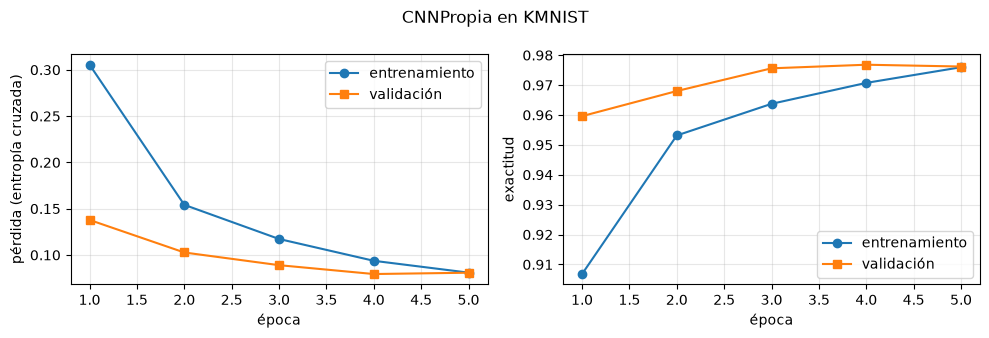

[OK]      TODO 3: la pérdida de entrenamiento baja entre la primera y la última época
[OK]      TODO 3: exactitud de validación > 80 %


True

In [10]:
# Entrenamiento y verificación TODO 3
fijar_semilla()
modelo = CNNPropia()
hist = entrenar(modelo, datos["dl_tr"], datos["dl_val"], epocas=EPOCAS, lr=1e-3)
graficar_curvas(hist, f"CNNPropia en {DATASET}")
verificar("TODO 3: la pérdida de entrenamiento baja entre la primera y la última época", hist["loss"][-1] < hist["loss"][0], "revise los 5 pasos y su orden")
verificar("TODO 3: exactitud de validación > 80 %", hist["val_acc"][-1] > 0.80, "con KMNIST o FashionMNIST reales debería superar 90 %; revise el entrenamiento")

## Paso 4 — TODO 4: evaluación en prueba y errores más frecuentes
Use el conjunto de prueba **una sola vez**. Encuentre el par (clase real, clase predicha) con más errores y **explique en el informe por qué cree que se confunden** (mire imágenes concretas).

Exactitud en prueba: 0.9334


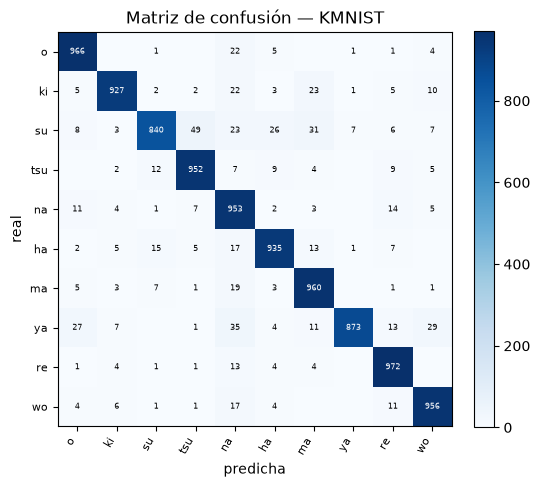

Par más confundido (real, predicha): ('su', 'tsu')
[OK]      TODO 4


np.True_

In [11]:
perd_te, acc_te, y_real, y_pred = evaluar(modelo, datos["dl_te"])
print(f"Exactitud en prueba: {acc_te:.4f}")
cm = confusion_matrix(y_real, y_pred)
graficar_confusion(cm, clases, f"Matriz de confusión — {DATASET}")

# ===== TODO 4: encuentre el par (real, predicha) con más errores, como tupla de dos enteros =====
# Pista: ponga en cero la diagonal de una copia de cm y use np.unravel_index(np.argmax(copia), copia.shape)
fuera = cm.copy(); np.fill_diagonal(fuera, 0)
par = tuple(int(v) for v in np.unravel_index(np.argmax(fuera), fuera.shape))
# ===== fin TODO 4 =====

_f = cm.copy(); np.fill_diagonal(_f, 0)
if par is not None:
    print("Par más confundido (real, predicha):", (clases[par[0]], clases[par[1]]))
verificar("TODO 4", par is not None and _f[tuple(par)] == _f.max(), "busque el máximo fuera de la diagonal")

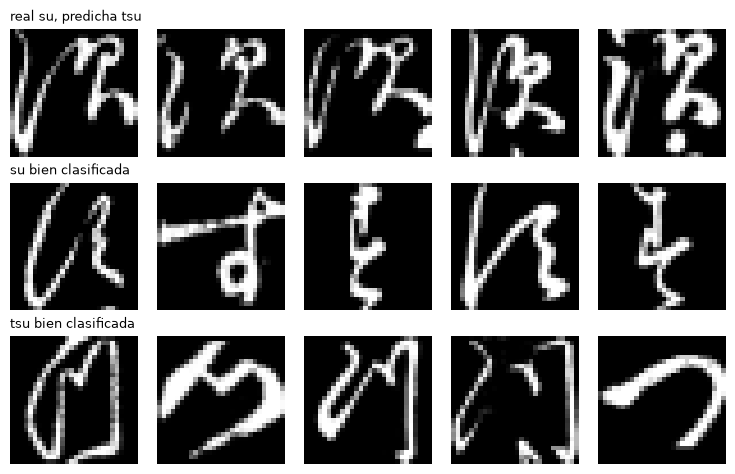

Errores de este par: 49 de 1000


In [12]:
# ===== Análisis adicional: ejemplos del par más confundido =====
real, pred = par
filas = [(np.where((y_real == real) & (y_pred == pred))[0][:5], f"real {clases[real]}, predicha {clases[pred]}"),
         (np.where((y_real == real) & (y_pred == real))[0][:5], f"{clases[real]} bien clasificada"),
         (np.where((y_real == pred) & (y_pred == pred))[0][:5], f"{clases[pred]} bien clasificada")]
fig, ejes = plt.subplots(3, 5, figsize=(7.5, 4.8))
for fila, (indices, titulo) in zip(ejes, filas):
    for ax, k in zip(fila, indices):
        ax.imshow(datos["Xraw_te"][k, 0], cmap="gray"); ax.axis("off")
    fila[0].set_title(titulo, fontsize=9, loc="left")
plt.tight_layout(); plt.show()
print("Errores de este par:", cm[real, pred], "de", cm[real].sum())

## Paso 5 — TODO 5: aumento de datos (experimento)
El **aumento de datos** crea variaciones de las imágenes de entrenamiento para que la red generalice mejor. Implemente un desplazamiento aleatorio de hasta ±2 píxeles y compare el modelo **con y sin** aumento, con la misma semilla y el mismo número de épocas.

*Para el informe:* ¿mejoró la exactitud de validación? ¿Cambió la brecha entre entrenamiento y validación? Si no mejoró, dígalo y proponga por qué.

In [13]:
# ===== TODO 5: devuelva xb desplazado al azar hasta +-max_px píxeles (un desplazamiento por lote es suficiente) =====
# Pista: torch.roll(xb, shifts=(dy, dx), dims=(2, 3)) con dy, dx enteros aleatorios
def aumentar_desplazamiento(xb, max_px=2):
    dy, dx = (int(v) for v in torch.randint(-max_px, max_px + 1, (2,)))
    return torch.roll(xb, shifts=(dy, dx), dims=(2, 3))
# ===== fin TODO 5 =====


In [14]:
# Verificación automática TODO 5
_x = datos["X_tr"][:8].to(dispositivo)
_cambios = [not torch.equal(aumentar_desplazamiento(_x), _x) for _ in range(30)]
verificar("TODO 5: conserva la forma del lote", aumentar_desplazamiento(_x).shape == _x.shape, "no cambie el tamaño")
verificar("TODO 5: modifica el lote en algunas llamadas", any(_cambios), "ahora devuelve xb sin cambios")

[OK]      TODO 5: conserva la forma del lote
[OK]      TODO 5: modifica el lote en algunas llamadas


True

In [15]:
# Comparación con y sin aumento (misma semilla y épocas)
filas = []
for etiqueta, aug in [("sin aumento", None), ("con aumento", aumentar_desplazamiento)]:
    fijar_semilla()
    m = CNNPropia()
    print("---", etiqueta)
    h_ = entrenar(m, datos["dl_tr"], datos["dl_val"], epocas=EPOCAS, lr=1e-3, aumentar=aug)
    _, a_te, _, _ = evaluar(m, datos["dl_te"])
    filas.append((etiqueta, h_["acc"][-1], h_["val_acc"][-1], a_te))
print("\n                 exact_entren  exact_valid  exact_prueba")
for e, a, v, t in filas:
    print(f"{e:<16} {a:.4f}        {v:.4f}       {t:.4f}")
print("\nAviso: con una sola semilla la diferencia puede ser ruido. Repita con 3 semillas antes de afirmar algo.")

--- sin aumento


época 1/5  pérdida 0.3129  exact 0.9047  |  val_pérdida 0.1570  val_exact 0.9540  (13s)


época 2/5  pérdida 0.1481  exact 0.9548  |  val_pérdida 0.0970  val_exact 0.9718  (13s)


época 3/5  pérdida 0.1164  exact 0.9649  |  val_pérdida 0.0947  val_exact 0.9690  (13s)


época 4/5  pérdida 0.0933  exact 0.9709  |  val_pérdida 0.0696  val_exact 0.9794  (13s)


...

época 2/5  pérdida 0.2582  exact 0.9211  |  val_pérdida 0.1239  val_exact 0.9596  (14s)


época 3/5  pérdida 0.2042  exact 0.9371  |  val_pérdida 0.0960  val_exact 0.9708  (13s)


época 4/5  pérdida 0.1713  exact 0.9466  |  val_pérdida 0.0698  val_exact 0.9808  (13s)


época 5/5  pérdida 0.1525  exact 0.9536  |  val_pérdida 0.0665  val_exact 0.9810  (13s)



                 exact_entren  exact_valid  exact_prueba
sin aumento      0.9755        0.9768       0.9292
con aumento      0.9536        0.9810       0.9342

Aviso: con una sola semilla la diferencia puede ser ruido. Repita con 3 semillas antes de afirmar algo.


In [16]:
# ===== Análisis adicional: la misma comparación con tres semillas =====
res = {"sin aumento": [], "con aumento": []}
for s in [42, 43, 44]:
    for etiqueta, aug in [("sin aumento", None), ("con aumento", aumentar_desplazamiento)]:
        fijar_semilla(s)
        m = CNNPropia()
        h_ = entrenar(m, datos["dl_tr"], datos["dl_val"], epocas=EPOCAS, lr=1e-3, aumentar=aug)
        _, a_te, _, _ = evaluar(m, datos["dl_te"])
        res[etiqueta].append((h_["acc"][-1], h_["val_acc"][-1], a_te))
print("\n                 exact_entren     exact_valid      exact_prueba    (media ± desviación, 3 semillas)")
for etiqueta, v in res.items():
    v = np.array(v)
    print(f"{etiqueta:<16} " + "   ".join(f"{m:.4f} ± {d:.4f}" for m, d in zip(v.mean(0), v.std(0))))

época 1/5  pérdida 0.3050  exact 0.9067  |  val_pérdida 0.1624  val_exact 0.9512  (13s)


época 2/5  pérdida 0.1531  exact 0.9534  |  val_pérdida 0.1006  val_exact 0.9696  (12s)


época 3/5  pérdida 0.1139  exact 0.9655  |  val_pérdida 0.0854  val_exact 0.9716  (13s)


época 4/5  pérdida 0.0953  exact 0.9704  |  val_pérdida 0.0834  val_exact 0.9738  (13s)


época 5/5  pérdida 0.0800  exact 0.9748  |  val_pérdida 0.0736  val_exact 0.9786  (13s)


...

época 2/5  pérdida 0.2640  exact 0.9185  |  val_pérdida 0.1137  val_exact 0.9674  (14s)


época 3/5  pérdida 0.2075  exact 0.9354  |  val_pérdida 0.0925  val_exact 0.9712  (13s)


época 4/5  pérdida 0.1798  exact 0.9444  |  val_pérdida 0.0854  val_exact 0.9738  (13s)


época 5/5  pérdida 0.1600  exact 0.9508  |  val_pérdida 0.0793  val_exact 0.9748  (13s)



                 exact_entren     exact_valid      exact_prueba    (media ± desviación, 3 semillas)
sin aumento      0.9750 ± 0.0001   0.9767 ± 0.0022   0.9326 ± 0.0045
con aumento      0.9520 ± 0.0015   0.9768 ± 0.0030   0.9299 ± 0.0038


## Paso 6 — (Opcional, para quienes trabajan en MATLAB) exportar las imágenes
MATLAB y su app **Deep Network Designer** leen las imágenes desde carpetas con un subdirectorio por clase. Esta celda guarda las imágenes en esa estructura y genera un `.zip` que puede descargar y descomprimir en su computador. Luego, en MATLAB:

```matlab
imds = imageDatastore("dataset_imagenes", IncludeSubfolders=true, LabelSource="foldernames");
```
Use el script `Taller5B_Propuesto_base.m` para seguir desde ahí.

In [17]:
def exportar_a_carpetas(X_raw, y, clases, carpeta="dataset_imagenes", max_por_clase=1000, comprimir=True):
    """Guarda imágenes PNG en carpeta/<clase>/NNNN.png: la estructura que MATLAB lee con
    imageDatastore(carpeta, IncludeSubfolders=true, LabelSource="foldernames") y con Deep Network Designer."""
    from PIL import Image
    if os.path.isdir(carpeta):
        shutil.rmtree(carpeta)
    cont = {}
    for i in range(len(y)):
        c = int(y[i]); nombre = str(clases[c]).replace("/", "_").replace(" ", "_")
        if cont.get(c, 0) >= max_por_clase:
            continue
        cont[c] = cont.get(c, 0) + 1
        os.makedirs(os.path.join(carpeta, nombre), exist_ok=True)
        arr = (X_raw[i, 0].numpy() * 255).round().astype("uint8")
        Image.fromarray(arr, mode="L").save(os.path.join(carpeta, nombre, f"{cont[c]:04d}.png"))
    total = sum(cont.values())
    print(f"Se guardaron {total} imágenes en {len(cont)} carpetas dentro de '{carpeta}'.")
    if comprimir:
        ruta = shutil.make_archive(carpeta, "zip", carpeta)
        print("Archivo comprimido:", ruta)
        return ruta
    return carpeta


In [ ]:
ruta_zip = exportar_a_carpetas(datos["Xraw_tr"], datos["y_tr"], clases, carpeta="dataset_imagenes", max_por_clase=1000)
try:
    from google.colab import files      # solo existe en Colab
    files.download(ruta_zip)
except ImportError:
    print("No está en Colab: el archivo quedó en", ruta_zip)